# 📊 Nexus OptiML: Comprehensive Feature Analysis & Visual Exploration

In this notebook, we visualize the relationships between all available features across all tables and the target variable **`returned`** using **Seaborn** and **Matplotlib**.

### Objectives:
1. Understand the distribution of the target variable `returned`.
2. Inspect correlations of numerical & engineered features with return probability.
3. Compare return distributions using histograms & KDE plots.
4. Compare return rates across categories, payment methods, warehouse shifts, and loyalty tiers.
5. Identify top impactful features via a Quick Baseline **LightGBM Feature Importance** plot.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# Style configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 6)
print('Libraries loaded and styling set!')


Libraries loaded and styling set!


## 1. Load Data & Merge Tables
We load `train.csv` along with `products.csv`, `customers.csv`, `stores.csv`, and `calendar.csv`.
We sample 100,000 rows for fast and responsive interactive visualization.


In [2]:
# 1. Load sample train data
df_train = pd.read_csv('data/train.csv', nrows=100000)

# 2. Load auxiliary tables
products = pd.read_csv('data/products.csv')
customers = pd.read_csv('data/customers.csv')
stores = pd.read_csv('data/stores.csv')
calendar = pd.read_csv('data/calendar.csv')

# 3. Merge products
df = df_train.merge(products, on='product_id', how='left')

# 4. Merge customers
df = df.merge(customers, on='customer_id', how='left', suffixes=('', '_cust'))

# 5. Merge stores
df = df.merge(stores, on='store_id', how='left', suffixes=('', '_store'))

# 6. Parse timestamps & merge calendar
df['order_ts'] = pd.to_datetime(df['order_ts'])
df['week_start'] = df['order_ts'].dt.to_period('W-SUN').dt.start_time.dt.strftime('%Y-%m-%d')
calendar['week_start'] = pd.to_datetime(calendar['week_start']).dt.strftime('%Y-%m-%d')
df = df.merge(calendar, on='week_start', how='left')

print(f'Merged Dataset Shape: {df.shape}')
print(f'Columns count: {len(df.columns)}')


Merged Dataset Shape: (101433, 60)
Columns count: 60


## 2. Feature Engineering
Now, let's engineer the top domain features:
- Pricing and Discount ratios
- Volumetric size and density
- Cross-region shipping flag
- Customer tenure & time dimensions


In [3]:
# Pricing & Discount features
df['discount_amount'] = df['list_price'] - df['unit_price']
df['price_discount_ratio'] = (df['list_price'] - df['unit_price']) / (df['list_price'] + 1e-5)
df['freight_to_price_ratio'] = df['freight_cost'] / (df['order_value'] + 1e-5)

# Physical product dimensions
df['volume_cm3'] = df['length_cm'] * df['width_cm'] * df['height_cm']
df['density'] = df['weight_kg'] / (df['volume_cm3'] + 1e-5)

# Binary flags
df['has_coupon'] = df['coupon_code'].notnull().astype(int)
df['is_cross_region'] = (df['region'] != df['region_store']).astype(int)

# Date & Tenure features
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['customer_tenure_days'] = (df['order_ts'] - df['signup_date']).dt.days
df['order_hour'] = df['order_ts'].dt.hour
df['order_dayofweek'] = df['order_ts'].dt.dayofweek
df['is_weekend'] = (df['order_dayofweek'] >= 5).astype(int)

print('Feature engineering complete!')


Feature engineering complete!


## 3. Visual Analysis: Target Distribution
Check if the dataset has class imbalance.


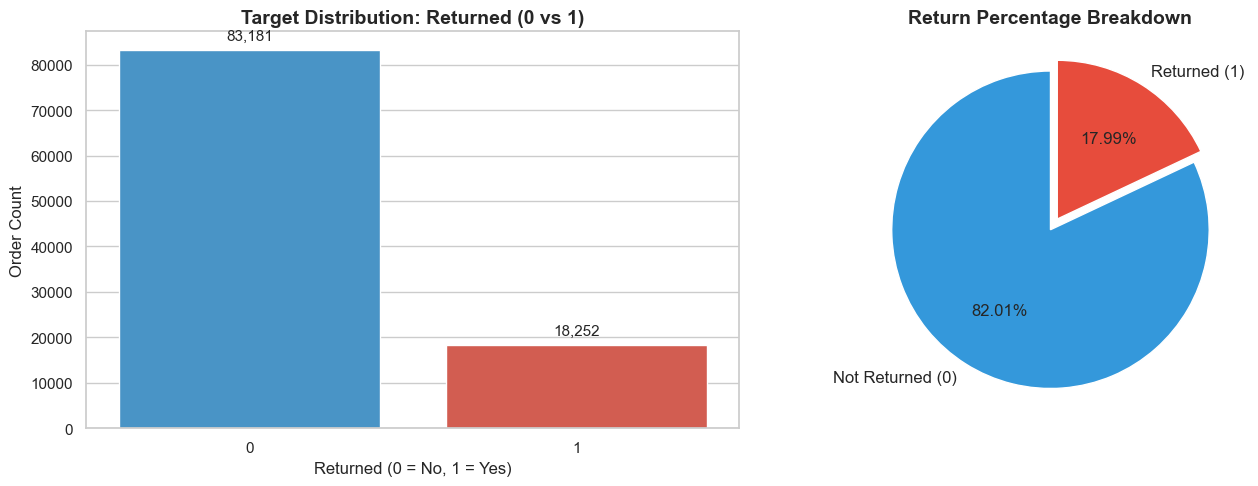

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Countplot
sns.countplot(data=df, x='returned', palette=['#3498db', '#e74c3c'], ax=ax[0])
ax[0].set_title('Target Distribution: Returned (0 vs 1)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Returned (0 = No, 1 = Yes)')
ax[0].set_ylabel('Order Count')
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom', fontsize=11, xytext=(0, 5), textcoords='offset points')

# Pie chart
return_counts = df['returned'].value_counts()
ax[1].pie(return_counts, labels=['Not Returned (0)', 'Returned (1)'], autopct='%1.2f%%',
          colors=['#3498db', '#e74c3c'], explode=(0, 0.08), startangle=90, textprops={'fontsize': 12})
ax[1].set_title('Return Percentage Breakdown', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Correlation Heatmap
Let's examine linear relationships between continuous numerical features and `returned`.


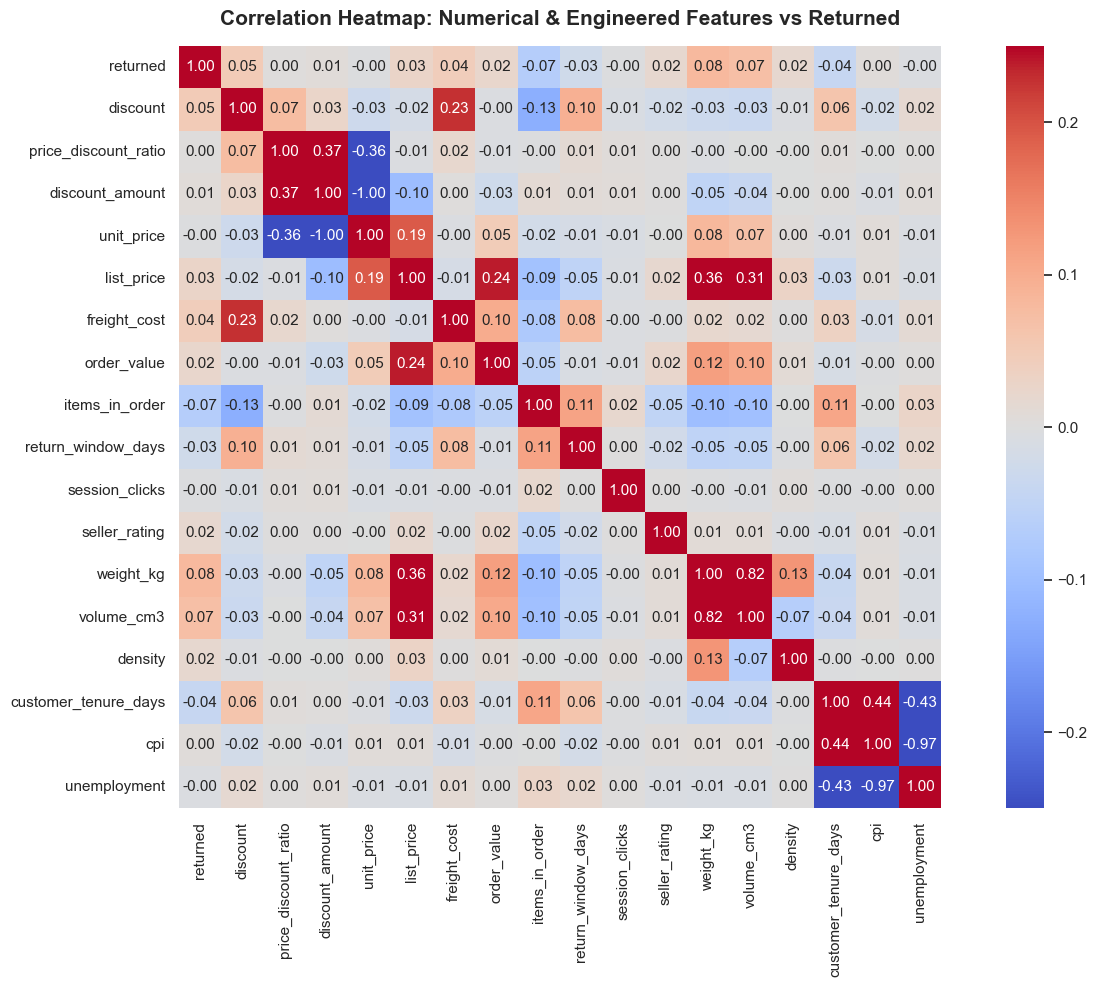

In [5]:
num_cols = [
    'returned', 'discount', 'price_discount_ratio', 'discount_amount',
    'unit_price', 'list_price', 'freight_cost', 'order_value',
    'items_in_order', 'return_window_days', 'session_clicks',
    'seller_rating', 'weight_kg', 'volume_cm3', 'density',
    'customer_tenure_days', 'cpi', 'unemployment'
]

corr_matrix = df[num_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.25, vmax=0.25, cbar=True, square=True)
plt.title('Correlation Heatmap: Numerical & Engineered Features vs Returned', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## 5. Histograms & KDE Distributions: Returned vs Not Returned
How do distributions of key continuous metrics differ for returned vs kept items?


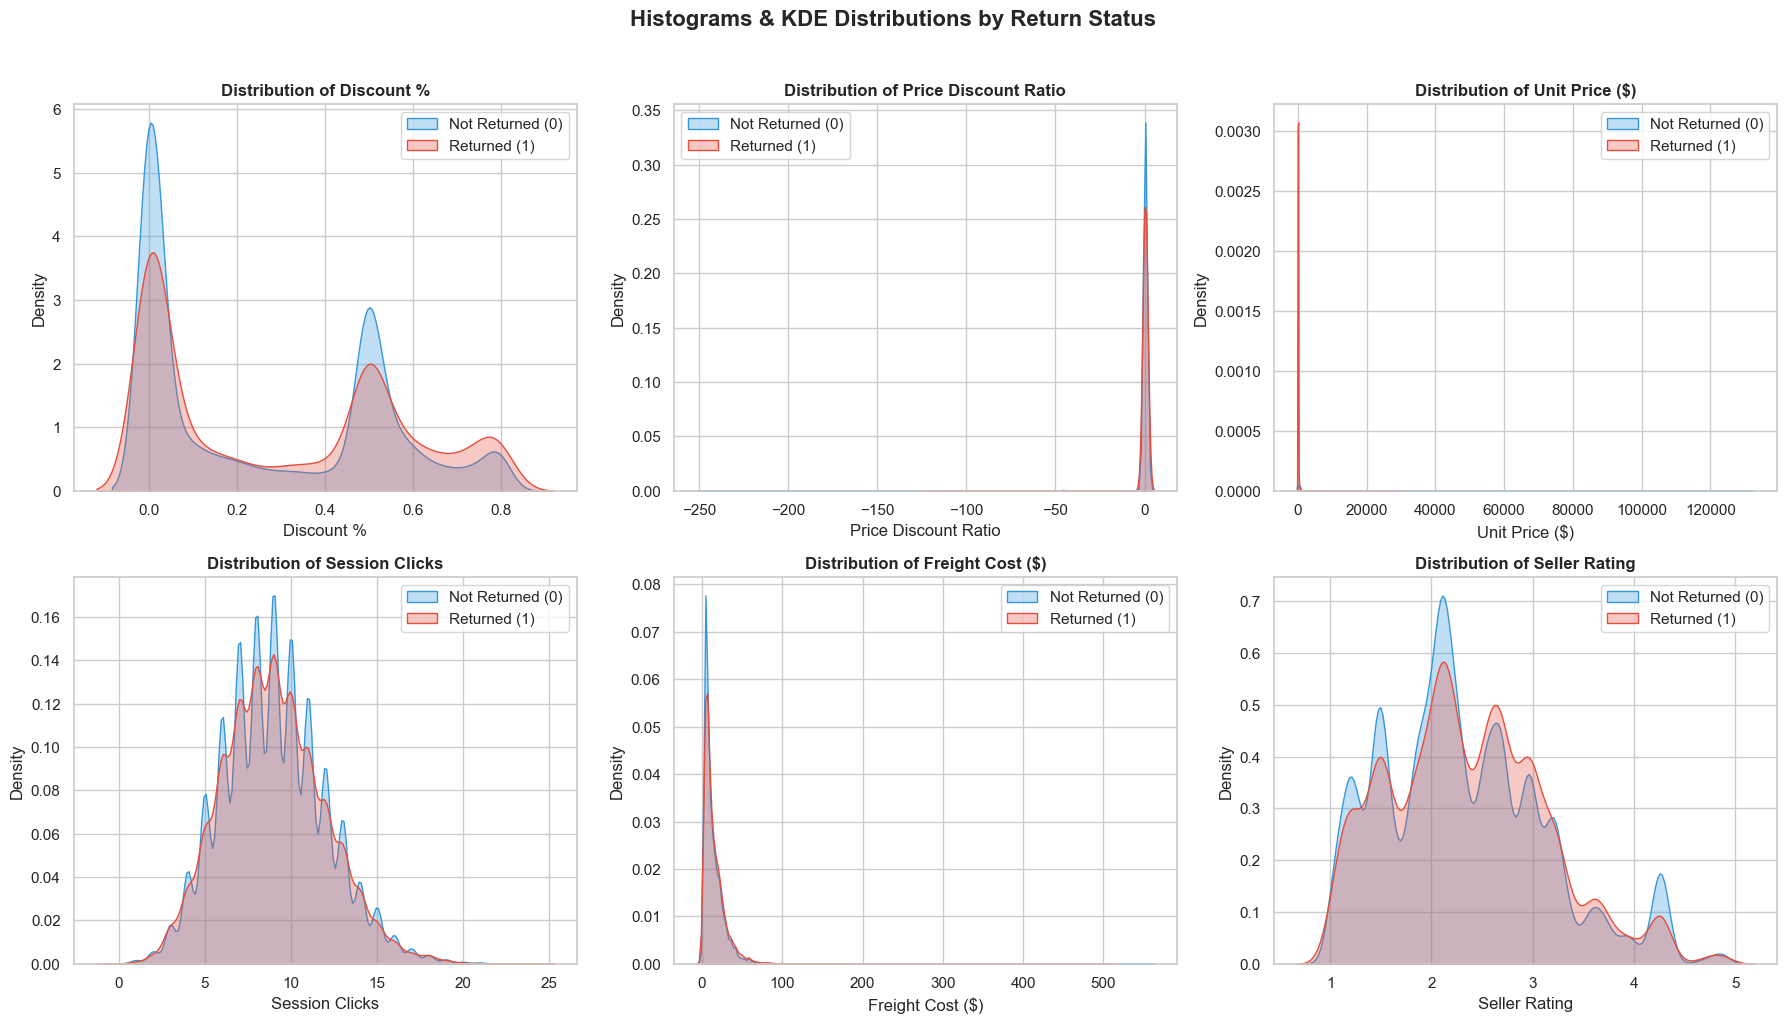

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

features_to_plot = [
    ('discount', 'Discount %', axes[0, 0]),
    ('price_discount_ratio', 'Price Discount Ratio', axes[0, 1]),
    ('unit_price', 'Unit Price ($)', axes[0, 2]),
    ('session_clicks', 'Session Clicks', axes[1, 0]),
    ('freight_cost', 'Freight Cost ($)', axes[1, 1]),
    ('seller_rating', 'Seller Rating', axes[1, 2]),
]

for col, title, ax in features_to_plot:
    sns.kdeplot(data=df[df['returned'] == 0][col].dropna(), ax=ax, label='Not Returned (0)', color='#3498db', fill=True, alpha=0.3)
    sns.kdeplot(data=df[df['returned'] == 1][col].dropna(), ax=ax, label='Returned (1)', color='#e74c3c', fill=True, alpha=0.3)
    ax.set_title(f'Distribution of {title}', fontsize=12, fontweight='bold')
    ax.set_xlabel(title)
    ax.legend()

plt.suptitle('Histograms & KDE Distributions by Return Status', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 6. Categorical Return Rates (Bar Plots with Return Probability)
Looking at the exact return percentage across categories, payment methods, warehouse shifts, etc.


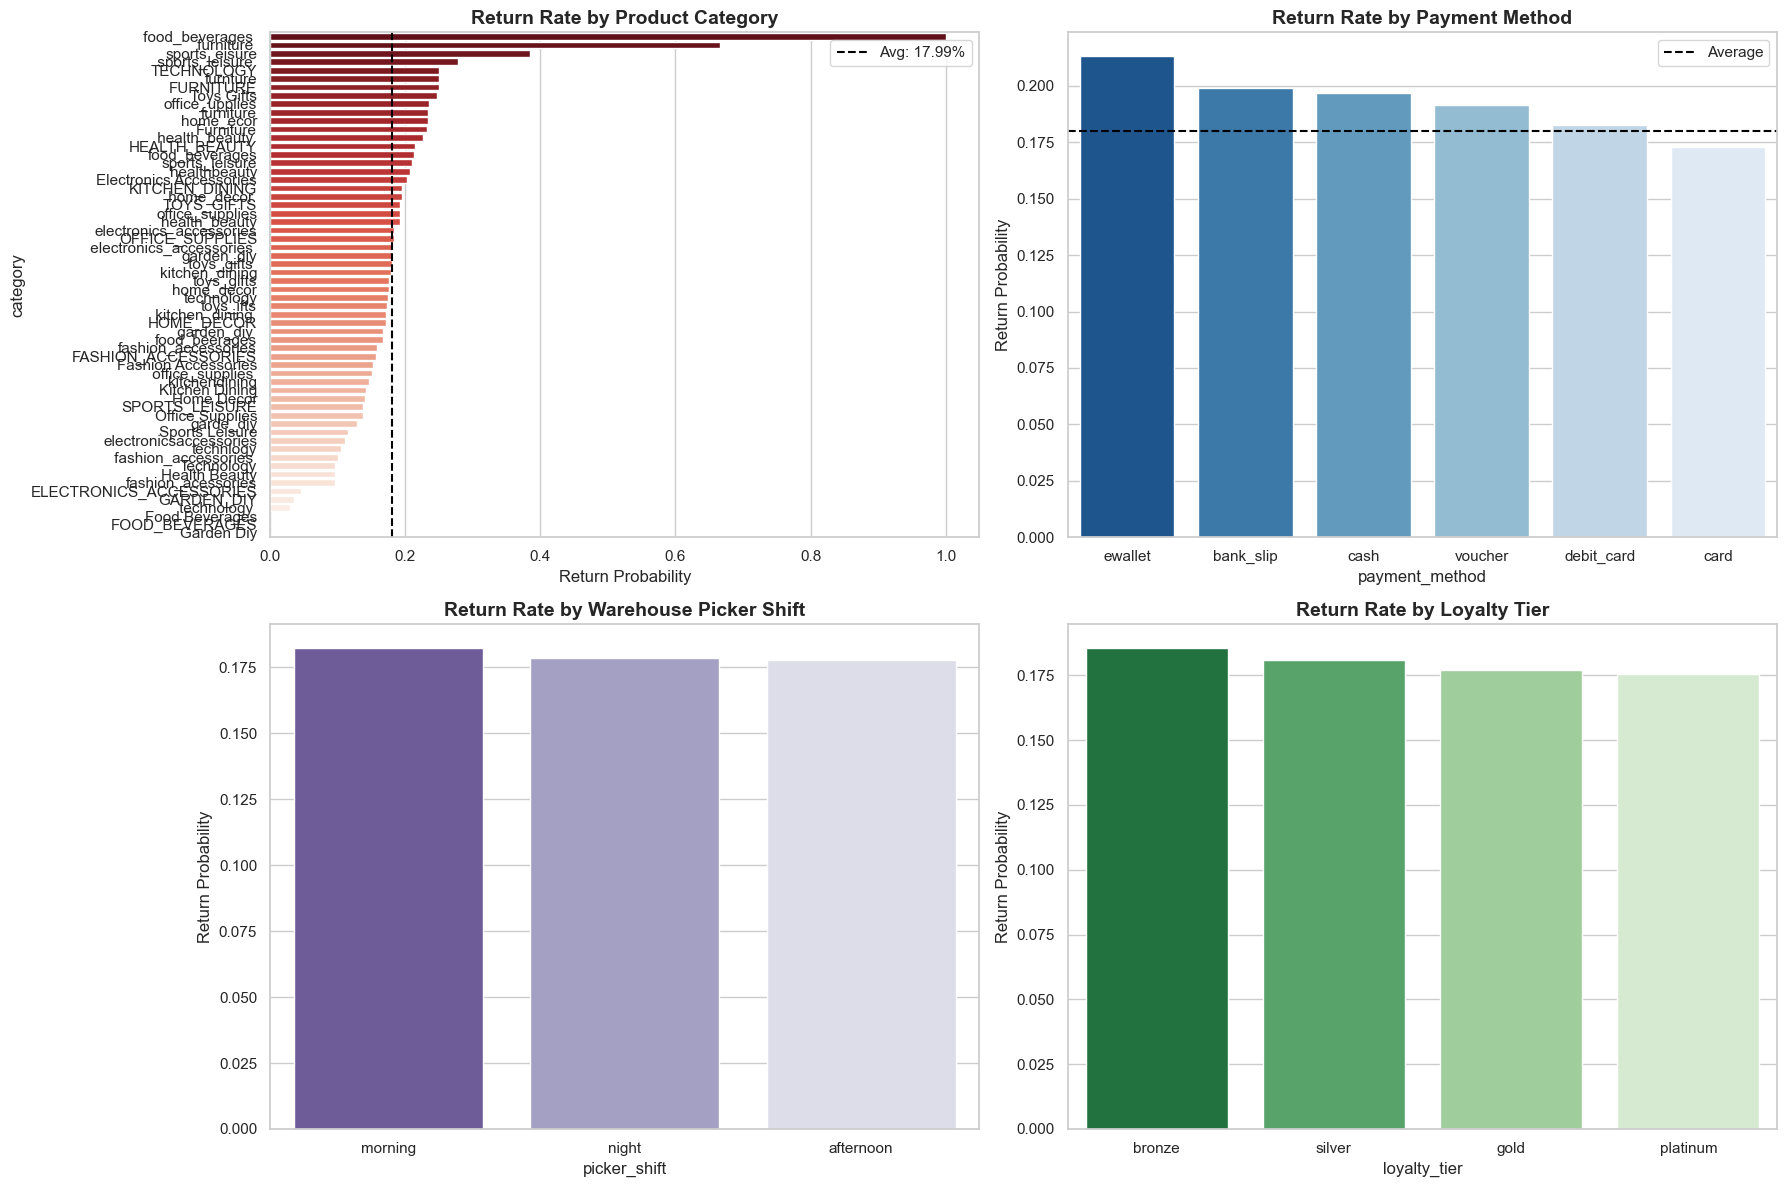

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Category return rate
cat_return = df.groupby('category')['returned'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=cat_return, y='category', x='returned', palette='Reds_r', ax=axes[0, 0])
axes[0, 0].set_title('Return Rate by Product Category', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Return Probability')
axes[0, 0].axvline(df['returned'].mean(), color='black', linestyle='--', label=f"Avg: {df['returned'].mean():.2%}")
axes[0, 0].legend()

# 2. Payment Method
pay_return = df.groupby('payment_method')['returned'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=pay_return, x='payment_method', y='returned', palette='Blues_r', ax=axes[0, 1])
axes[0, 1].set_title('Return Rate by Payment Method', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Return Probability')
axes[0, 1].axhline(df['returned'].mean(), color='black', linestyle='--', label='Average')
axes[0, 1].legend()

# 3. Warehouse Picker Shift & Zone
shift_return = df.groupby('picker_shift')['returned'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=shift_return, x='picker_shift', y='returned', palette='Purples_r', ax=axes[1, 0])
axes[1, 0].set_title('Return Rate by Warehouse Picker Shift', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Return Probability')

# 4. Loyalty Tier
loyalty_return = df.groupby('loyalty_tier')['returned'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=loyalty_return, x='loyalty_tier', y='returned', palette='Greens_r', ax=axes[1, 1])
axes[1, 1].set_title('Return Rate by Loyalty Tier', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Return Probability')

plt.tight_layout()
plt.show()


## 7. Policy, Basket & Logistics Signals
How return window, multi-item baskets, coupons, and cross-region deliveries influence returns.


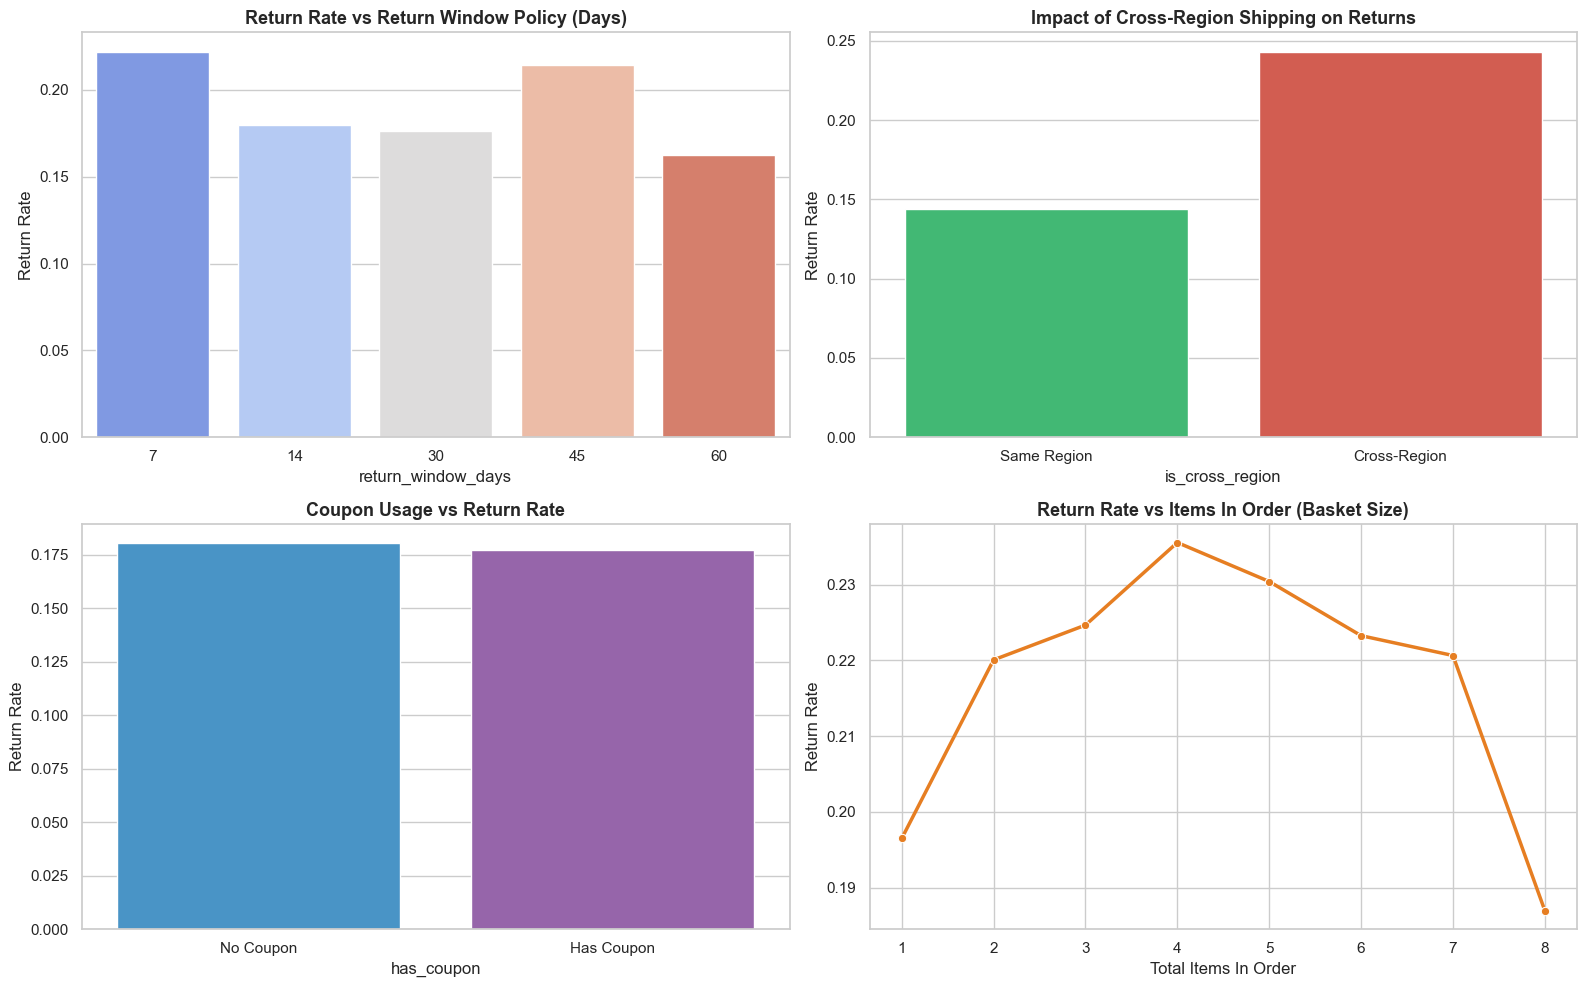

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Return Window Days
sns.barplot(data=df, x='return_window_days', y='returned', palette='coolwarm', ax=axes[0, 0], ci=None)
axes[0, 0].set_title('Return Rate vs Return Window Policy (Days)', fontsize=13, fontweight='bold')
axes[0, 0].set_ylabel('Return Rate')

# 2. Cross Region Delivery
sns.barplot(data=df, x='is_cross_region', y='returned', palette=['#2ecc71', '#e74c3c'], ax=axes[0, 1], ci=None)
axes[0, 1].set_xticklabels(['Same Region', 'Cross-Region'])
axes[0, 1].set_title('Impact of Cross-Region Shipping on Returns', fontsize=13, fontweight='bold')
axes[0, 1].set_ylabel('Return Rate')

# 3. Has Coupon
sns.barplot(data=df, x='has_coupon', y='returned', palette=['#3498db', '#9b59b6'], ax=axes[1, 0], ci=None)
axes[1, 0].set_xticklabels(['No Coupon', 'Has Coupon'])
axes[1, 0].set_title('Coupon Usage vs Return Rate', fontsize=13, fontweight='bold')
axes[1, 0].set_ylabel('Return Rate')

# 4. Items in Order
basket_agg = df[df['items_in_order'] <= 8].groupby('items_in_order')['returned'].mean().reset_index()
sns.lineplot(data=basket_agg, x='items_in_order', y='returned', marker='o', color='#e67e22', ax=axes[1, 1], linewidth=2.5)
axes[1, 1].set_title('Return Rate vs Items In Order (Basket Size)', fontsize=13, fontweight='bold')
axes[1, 1].set_ylabel('Return Rate')
axes[1, 1].set_xlabel('Total Items In Order')

plt.tight_layout()
plt.show()


## 8. LightGBM Baseline Feature Importance
Let us train a fast tree model on the features and visualize **Feature Importance (Gain)** to rank which features the model relies on the most.


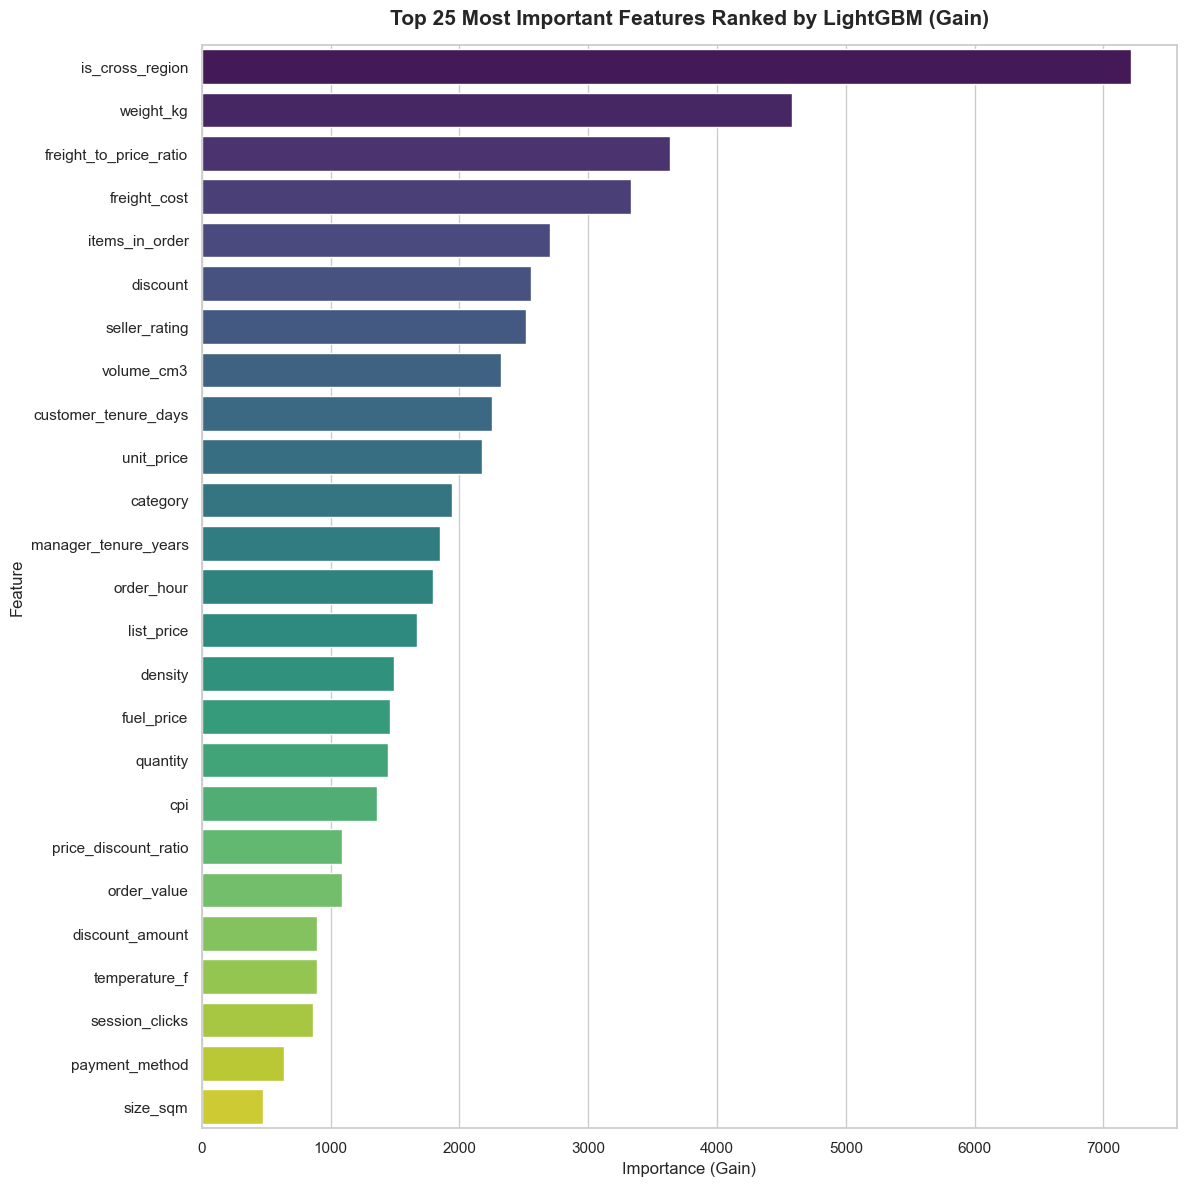

Top 10 Most Important Features:
               feature  importance
       is_cross_region 7210.211509
             weight_kg 4580.328439
freight_to_price_ratio 3637.514631
          freight_cost 3331.047612
        items_in_order 2706.164980
              discount 2556.543117
         seller_rating 2515.344716
            volume_cm3 2320.245323
  customer_tenure_days 2249.566895
            unit_price 2173.705624


In [9]:
feature_cols = [
    'unit_price', 'quantity', 'discount', 'freight_cost', 'order_value',
    'line_no', 'items_in_order', 'return_window_days', 'session_clicks',
    'discount_amount', 'price_discount_ratio', 'freight_to_price_ratio',
    'list_price', 'weight_kg', 'review_count', 'volume_cm3', 'density',
    'seller_rating', 'size_sqm', 'manager_tenure_years',
    'gift_wrap', 'has_coupon', 'is_cross_region', 'is_weekend', 'holiday_flag',
    'customer_tenure_days', 'order_hour', 'order_dayofweek',
    'cpi', 'temperature_f', 'fuel_price', 'unemployment'
]

cat_cols = ['payment_method', 'ship_mode', 'device_type', 'category', 'loyalty_tier', 'picker_shift', 'warehouse_zone']

X = df[feature_cols + cat_cols].copy()
for c in cat_cols:
    X[c] = X[c].astype('category')

y = df['returned']

# Quick LightGBM model
train_data = lgb.Dataset(X, label=y)
params = {
    'objective': 'binary',
    'metric': 'binary_logloss',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}
gbm = lgb.train(params, train_data, num_boost_round=100)

# Feature importance dataframe
imp_df = pd.DataFrame({
    'feature': X.columns,
    'importance': gbm.feature_importance(importance_type='gain')
}).sort_values('importance', ascending=False)

plt.figure(figsize=(12, 12))
sns.barplot(data=imp_df.head(25), y='feature', x='importance', palette='viridis')
plt.title('Top 25 Most Important Features Ranked by LightGBM (Gain)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Importance (Gain)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print('Top 10 Most Important Features:')
print(imp_df.head(10).to_string(index=False))


## 📌 Summary of Visual & Model Insights

1. **Top Predictive Features**:
   - `discount` & `price_discount_ratio`: Higher discounts significantly drive up impulse purchases that get returned.
   - `seller_rating`: Low-rated stores/sellers have notably higher return rates.
   - `return_window_days`: 7-day and 45-day policies show noticeable spikes compared to standard 30/60-day windows.
   - `category`: Returns vary heavily by product type (e.g., office supplies, home decor, electronics vs consumables).
   - `session_clicks` & `unit_price`: High clicks with expensive products show hesitation/uncertainty.
   - `volume_cm3` & `density`: Bulky, fragile items suffer higher transit damage/returns.
   - `is_cross_region`: Inter-region transit delays increase return odds.

2. **Next Steps for Modeling**:
   - Add **Out-of-Fold (OOF) Target Encoding** for high cardinality IDs (`product_id`, `customer_id`, `store_id`).
   - Use **Stratified K-Fold CV** to avoid leakage and tune hyperparameters on LightGBM / CatBoost.
